# CNN on MNIST: a first PyTorch image-classification model

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/neural-networks/04-mnist-cnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

In the preceding notebook, a filter produced a feature map by sliding
across an input. Here, a convolutional neural network learns its own
filters from labeled handwritten-digit images. This is also a first
end-to-end PyTorch workflow: dataset, mini-batches, model, loss,
backpropagation, parameter update, and held-out evaluation.

## What you will do

1. Load MNIST images as tensors and create mini-batches.
2. Train a fully connected network as a baseline.
3. Define a small CNN and trace the tensor shape through it.
4. Train the CNN and compare both models.

## 1. Load and inspect MNIST

MNIST contains `28 × 28` grayscale images of handwritten digits.
Each pixel has one intensity value, so PyTorch represents one image as
`(channels, height, width) = (1, 28, 28)`. The CNN receives a mini-batch
with shape `(batch_size, 1, 28, 28)` and a
matching integer label from 0 through 9 for every image.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch  # Tensors, automatic differentiation, and hardware support.
from torch import nn  # Neural-network layers and loss functions.
from torch.nn import functional as F  # Stateless operations such as ReLU.
from torch.utils.data import DataLoader  # Mini-batch iterator for a Dataset.
from torchvision import datasets, transforms  # Standard vision data utilities.


SEED = 4520
DATA_ROOT = Path("data")
MODEL_DIR = DATA_ROOT / "mnist-models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)  # Local, untracked model checkpoints.
BATCH_SIZE = 64

# Fix the random choices so repeated runs start from the same weights and
# present mini-batches in the same order.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

# A PyTorch device specifies the hardware used to store tensors and run
# calculations. The model and its input tensors must be on the same device.
if torch.cuda.is_available():
    device = torch.device("cuda")  # Use an NVIDIA GPU when available.
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # Use the GPU on an Apple Silicon Mac.
else:
    device = torch.device("cpu")  # Portable fallback; usually slower.

print(f"Using device: {device}")

Using device: mps


In [2]:
# `ToTensor()` converts one PIL image into a float32 tensor with shape
# `(channels, height, width)` and pixel values between 0 and 1.
display_transform = transforms.ToTensor()
# `Compose` applies transformations in order whenever a dataset example is requested.
train_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        # Center and scale the single image channel using MNIST statistics.
        transforms.Normalize(mean=(0.1307,), std=(0.3081,)),
    ]
)

# A torchvision Dataset returns one `(image_tensor, integer_label)` pair
# when we index it. Keep one unnormalized copy for easy visualization.
mnist_display = datasets.MNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=display_transform,
)
# `train=True` selects the 60,000-image training split.
mnist_train = datasets.MNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=train_transform,
)
# `train=False` selects the separate 10,000-image test split.
mnist_test = datasets.MNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=train_transform,
)

print(f"Training images: {len(mnist_train):,}")
print(f"Test images:     {len(mnist_test):,}")

Training images: 60,000
Test images:     10,000


One image shape: (1, 28, 28)
Its label:        5


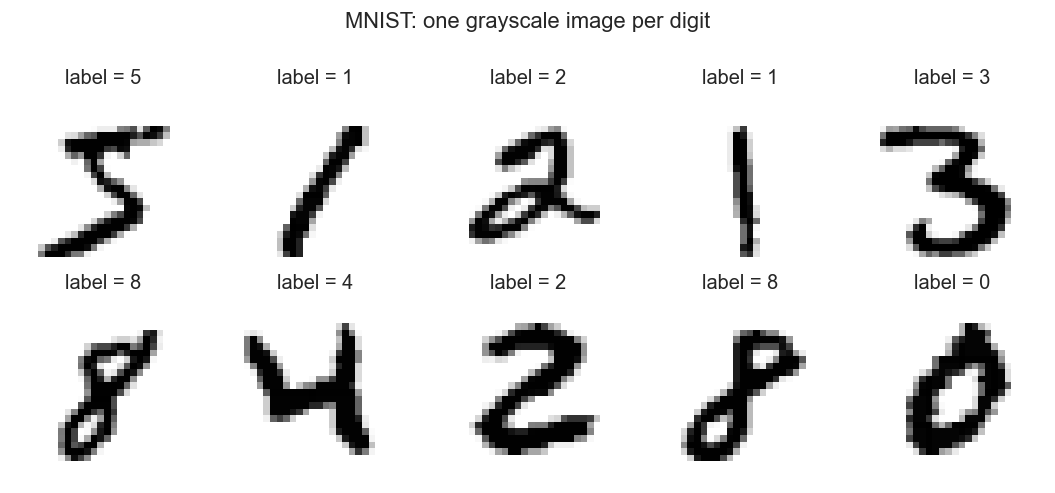

In [3]:
def show_digit_examples(
    *, dataset: datasets.MNIST, positions: list[int]
) -> None:
    """Display selected MNIST images and their labels.

    Args:
        dataset: MNIST dataset containing images and labels.
        positions: Dataset positions to display.
    """
    figure, axes = plt.subplots(2, 5, figsize=(9, 4))
    for axis, position in zip(axes.ravel(), positions):
        image, label = dataset[position]
        axis.imshow(image.squeeze(), cmap="gray_r", vmin=0, vmax=1)
        axis.set_title(f"label = {label}")
        axis.axis("off")
    figure.suptitle("MNIST: one grayscale image per digit", y=1.02)
    figure.tight_layout()


EXAMPLE_POSITIONS = [0, 3, 5, 8, 12, 17, 20, 25, 31, 37]
show_digit_examples(dataset=mnist_display, positions=EXAMPLE_POSITIONS)

image, label = mnist_display[EXAMPLE_POSITIONS[0]]
print(f"One image shape: {tuple(image.shape)}")
print(f"Its label:        {label}")

## 2. Train an MLP baseline

First, let's classify the same images with a **multilayer perceptron (MLP)**. It
flattens each image into 784 values, then uses fully connected layers.
We will use the same data, batch size, optimizer, and number of epochs
for both models. Compare their accuracy and number of parameters; a CNN
does not necessarily outperform an MLP on every run.

In [4]:
# Flatten each image, then apply three fully connected hidden layers.
torch.manual_seed(SEED)
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 10),  # Output logits for the ten digits.
).to(device)
mlp_train_loader = DataLoader(mnist_train, batch_size=BATCH_SIZE, shuffle=True)
mlp_test_loader = DataLoader(mnist_test, batch_size=BATCH_SIZE, shuffle=False)
mlp_loss = nn.CrossEntropyLoss()
mlp_optimizer = torch.optim.Adam(params=mlp.parameters(), lr=1e-3)

for epoch in range(1, 31):
    mlp.train()
    for images, labels in mlp_train_loader:
        images, labels = images.to(device), labels.to(device)
        mlp_optimizer.zero_grad()
        loss = mlp_loss(mlp(images), labels)
        loss.backward()
        mlp_optimizer.step()
    if epoch % 10 == 0:
        print(f"MLP: finished epoch {epoch}")

mlp.eval()
mlp_correct = 0
with torch.no_grad():
    for images, labels in mlp_test_loader:
        images, labels = images.to(device), labels.to(device)
        mlp_correct += (mlp(images).argmax(dim=1) == labels).sum().item()
mlp_test_accuracy = mlp_correct / len(mnist_test)
mlp_parameters = sum(parameter.numel() for parameter in mlp.parameters())
print(f"MLP test accuracy: {mlp_test_accuracy:.3f}")
print(f"MLP trainable parameters: {mlp_parameters:,}")
# Save weights and training details so the fitted model can be reused.
torch.save({
    "model_state_dict": mlp.state_dict(),
    "optimizer_state_dict": mlp_optimizer.state_dict(),
    "architecture": [784, 256, 128, 64, 10],
    "normalization": {"mean": 0.1307, "std": 0.3081},
    "epochs": 30, "batch_size": BATCH_SIZE, "seed": SEED,
}, MODEL_DIR / "mlp.pt")

MLP: finished epoch 10


MLP: finished epoch 20


MLP: finished epoch 30


MLP test accuracy: 0.980
MLP trainable parameters: 242,762


## 3. Define a small CNN

The network has two convolutional stages. Each stage learns several
feature maps, applies ReLU, and then uses max pooling to reduce spatial
resolution. The final classifier maps the learned features to ten digit
scores, called **logits**.

In [5]:
class SmallCNN(nn.Module):
    """Classify 28-by-28 grayscale digit images with two convolutional stages."""

    def __init__(self) -> None:
        """Initialize the convolutional feature extractor and digit classifier."""
        # `nn.Module` tracks the layers and their learnable parameters.
        super().__init__()
        # Each `Conv2d` layer learns local filters. `padding=1` keeps
        # height and width unchanged before pooling.
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=8,
            kernel_size=3,
            padding=1,
        )
        self.conv2 = nn.Conv2d(
            in_channels=8,
            out_channels=16,
            kernel_size=3,
            padding=1,
        )
        # Max pooling keeps the strongest response in each 2-by-2 neighborhood.
        self.pool = nn.MaxPool2d(kernel_size=2)
        # `nn.Sequential` sends its input through these layers in order.
        self.classifier = nn.Sequential(
            # Flatten turns the final feature maps into one vector per image.
            nn.Flatten(),
            nn.Linear(in_features=16 * 7 * 7, out_features=64),
            nn.ReLU(),  # Elementwise nonlinearity: max(0, value).
            # Ten unnormalized class scores (logits), not probabilities.
            nn.Linear(in_features=64, out_features=10),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        """Return one unnormalized score for each digit class.

        Args:
            images: Image batch with shape `(batch, 1, 28, 28)`.

        Returns:
            Logits with shape `(batch, 10)`.
        """
        # Calling `model(images)` invokes this forward-pass method.
        features = self.pool(F.relu(self.conv1(images)))
        features = self.pool(F.relu(self.conv2(features)))
        # Do not add softmax here: CrossEntropyLoss applies it internally.
        return self.classifier(features)


def count_trainable_parameters(*, model: nn.Module) -> int:
    """Count a model's trainable scalar parameters.

    Args:
        model: PyTorch model whose parameters will be counted.

    Returns:
        Number of trainable scalar parameters.
    """
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


# `.to(device)` moves every learnable weight and bias to the chosen hardware.
model = SmallCNN().to(device)
print(model)
print(f"Trainable parameters: {count_trainable_parameters(model=model):,}")

SmallCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 52,138


In [6]:
def show_intermediate_shapes(*, model: SmallCNN, images: torch.Tensor) -> None:
    """Print the tensor shape after each main CNN operation.

    Args:
        model: CNN whose operations will be traced.
        images: Input images with shape `(batch, 1, 28, 28)`.
    """
    # Shape inspection does not need gradients, so skip a gradient graph.
    with torch.no_grad():
        first_convolution = model.conv1(images)
        first_pool = model.pool(F.relu(first_convolution))
        second_convolution = model.conv2(first_pool)
        second_pool = model.pool(F.relu(second_convolution))
        logits = model.classifier(second_pool)

    named_tensors = [
        ("input images", images),
        ("after first convolution", first_convolution),
        ("after first pooling", first_pool),
        ("after second convolution", second_convolution),
        ("after second pooling", second_pool),
        ("digit logits", logits),
    ]
    for name, tensor in named_tensors:
        print(f"{name:28s} {tuple(tensor.shape)}")


# A DataLoader groups individual Dataset examples into mini-batches.
shape_images, _ = next(iter(DataLoader(mnist_train, batch_size=4, shuffle=False)))
# These images are on the CPU, so temporarily move the model there as well.
show_intermediate_shapes(model=model.cpu(), images=shape_images)
model = model.to(device)

input images                 (4, 1, 28, 28)
after first convolution      (4, 8, 28, 28)
after first pooling          (4, 8, 14, 14)
after second convolution     (4, 16, 14, 14)
after second pooling         (4, 16, 7, 7)
digit logits                 (4, 10)


A CNN uses the structural assumption that nearby pixels matter together, and
useful local patterns may occur anywhere in the image.

## 4. Train the CNN

`CrossEntropyLoss` accepts logits directly and combines softmax with
multi-class cross-entropy internally. Its result is averaged over each
mini-batch.

In [7]:
# A DataLoader repeatedly yields mini-batches of `(images, labels)`. Shuffling
# changes the training order every epoch; we preserve test-set order.
train_loader = DataLoader(
    mnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
test_loader = DataLoader(
    mnist_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)


def train_one_epoch(
    *,
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    loss_function: nn.Module,
    device: torch.device,
) -> tuple[float, float]:
    """Train a model for one pass through a dataset.

    Args:
        model: CNN to train.
        loader: Mini-batches of images and integer labels.
        optimizer: Optimizer that applies parameter updates.
        loss_function: Loss evaluated from logits and labels.
        device: Device on which calculations are performed.

    Returns:
        Mean loss and classification accuracy across the dataset.
    """
    # Enable training-specific layer behavior (for example, dropout later).
    model.train()
    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0

    for images, labels in loader:
        # The mini-batch must occupy the same device as the model.
        images = images.to(device)
        labels = labels.to(device)

        # PyTorch accumulates gradients by default, so clear the previous batch.
        optimizer.zero_grad()
        logits = model(images)  # Forward pass: ten raw scores per image.
        # CrossEntropyLoss accepts raw logits and integer class labels.
        loss = loss_function(logits, labels)
        loss.backward()  # Backpropagation: compute and store parameter gradients.
        optimizer.step()  # Use those gradients to update the parameters.

        batch_size = labels.size(0)
        # `.item()` converts a one-value PyTorch tensor into a Python number.
        total_loss += loss.item() * batch_size
        correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, correct_predictions / total_examples


def evaluate(
    *,
    model: nn.Module,
    loader: DataLoader,
    loss_function: nn.Module,
    device: torch.device,
) -> tuple[float, float, np.ndarray, np.ndarray, np.ndarray]:
    """Evaluate a model without changing its parameters.

    Args:
        model: CNN to evaluate.
        loader: Mini-batches of images and integer labels.
        loss_function: Loss evaluated from logits and labels.
        device: Device on which calculations are performed.

    Returns:
        Mean loss, accuracy, true labels, predicted labels, and probabilities.
    """
    # Switch to inference behavior: notably, disable dropout.
    model.eval()
    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0
    all_labels: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    # We do not update parameters here, so gradients waste time and memory.
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_function(logits, labels)
            # Softmax turns ten logits into ten probabilities that sum to one.
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct_predictions += (predictions == labels).sum().item()
            total_examples += batch_size
            # NumPy and scikit-learn need CPU arrays, not GPU/MPS tensors.
            all_labels.append(labels.cpu().numpy())
            all_predictions.append(predictions.cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())

    return (
        total_loss / total_examples,
        correct_predictions / total_examples,
        np.concatenate(all_labels),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


torch.manual_seed(SEED)  # Reproducible CNN initialization.
model = SmallCNN().to(device)
# This loss combines softmax with cross-entropy in a numerically stable way.
loss_function = nn.CrossEntropyLoss()
# Adam is the update rule; `model.parameters()` supplies all learnable values.
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-3)

EPOCHS = 30
history = {"train_loss": [], "train_accuracy": [], "test_loss": [], "test_accuracy": []}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        loss_function=loss_function,
        device=device,
    )
    test_loss, test_accuracy, _, _, _ = evaluate(
        model=model,
        loader=test_loader,
        loss_function=loss_function,
        device=device,
    )
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_accuracy)
    if epoch % 10 == 0:
        print(
            f"Epoch {epoch}: "
            f"train loss = {train_loss:.3f}; test loss = {test_loss:.3f}; "
            f"train accuracy = {train_accuracy:.3f}; "
            f"test accuracy = {test_accuracy:.3f}"
        )

# Save the trained CNN, optimizer, and learning curves for later use.
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "architecture": "SmallCNN",
    "normalization": {"mean": 0.1307, "std": 0.3081},
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "seed": SEED,
    "history": history,
}, MODEL_DIR / "cnn.pt")

Epoch 10: train loss = 0.014; test loss = 0.039; train accuracy = 0.995; test accuracy = 0.987


Epoch 20: train loss = 0.006; test loss = 0.051; train accuracy = 0.998; test accuracy = 0.988


Epoch 30: train loss = 0.003; test loss = 0.049; train accuracy = 0.999; test accuracy = 0.990


Comparing training and test curves helps us see how well the model
generalizes. Accuracy counts correct predictions, while cross-entropy
also reflects the confidence assigned to each correct label. The test
loss can therefore rise as the model becomes more confident in its
mistakes, even when test accuracy stays roughly the same. A widening
train–test loss gap can be a sign of overfitting.

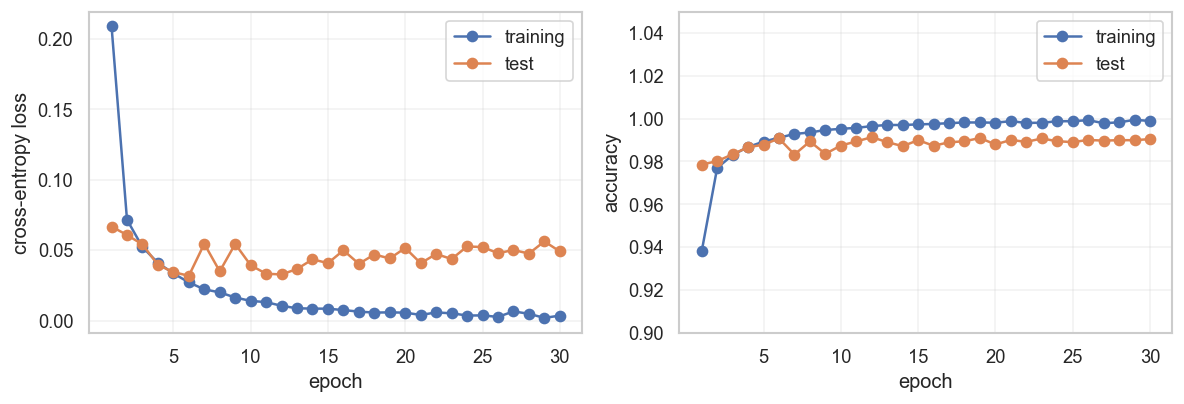

In [8]:
epochs = np.arange(1, EPOCHS + 1)
plot_ticks = np.arange(5, EPOCHS + 1, 5)
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(epochs, history["train_loss"], marker="o", label="training")
axes[0].plot(epochs, history["test_loss"], marker="o", label="test")
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", xticks=plot_ticks)
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="training")
axes[1].plot(epochs, history["test_accuracy"], marker="o", label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", xticks=plot_ticks, ylim=(0.9, 1.05))
axes[1].legend()
axes[1].grid(alpha=0.25)

figure.tight_layout()

## 5. Visualize learned filters and feature maps

The first convolutional layer learns eight 3 × 3 filters. For one test
image, let's compare those weights with their feature maps after ReLU.
Bright regions in a feature map show where that filter responds strongly.
A filter may respond to a local stroke or edge, although learned filters
do not always have a simple human-readable interpretation. The model sees
the normalized version of the image shown here.

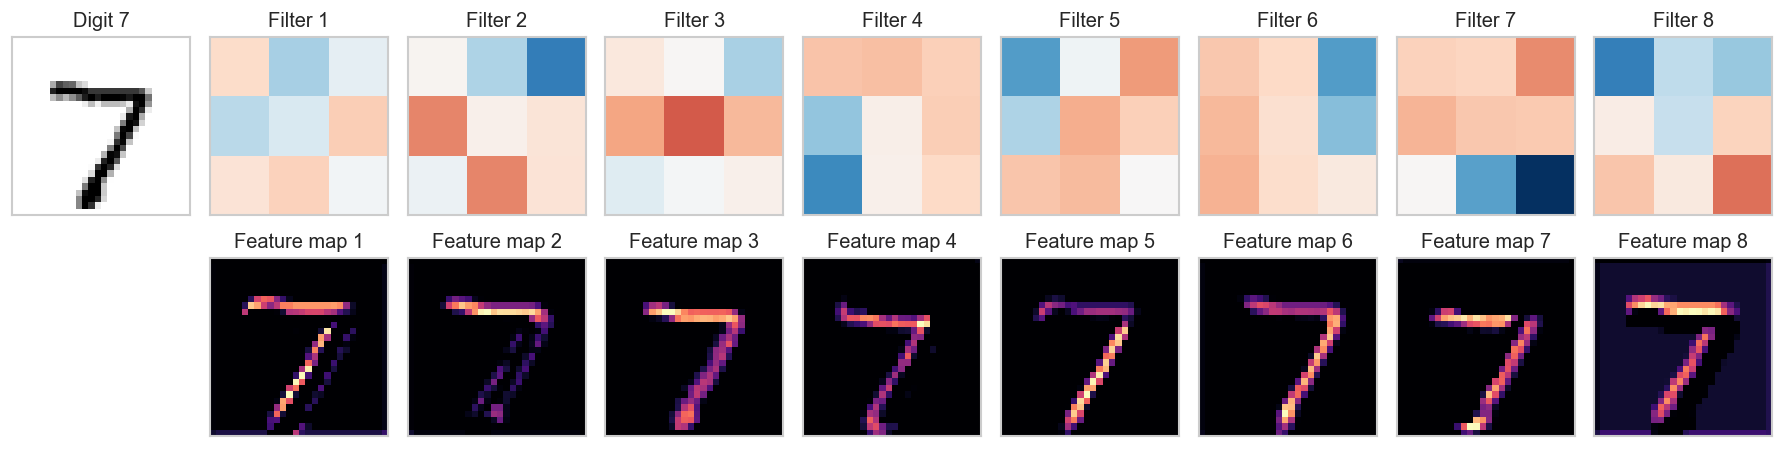

In [9]:
# Pick a test digit and pass its normalized image through the first layer.
example_image, example_label = mnist_test[0]
model.eval()
with torch.no_grad():
    feature_maps = F.relu(model.conv1(example_image.unsqueeze(0).to(device)))

filters = model.conv1.weight.detach().cpu().numpy()[:, 0]
feature_maps = feature_maps.squeeze(0).cpu().numpy()
# Show the unnormalized image for easier visual interpretation.
display_image, _ = datasets.MNIST(root=DATA_ROOT, train=False, download=True,
                                  transform=display_transform)[0]
figure, axes = plt.subplots(2, 9, figsize=(15, 4))
axes[0, 0].imshow(display_image.squeeze(), cmap="gray_r", vmin=0, vmax=1)
axes[0, 0].set_title(f"Digit {example_label}")
axes[1, 0].axis("off")
weight_limit = np.abs(filters).max()
for index in range(8):
    axes[0, index + 1].imshow(filters[index], cmap="RdBu_r",
                               vmin=-weight_limit, vmax=weight_limit)
    axes[0, index + 1].set_title(f"Filter {index + 1}")
    axes[1, index + 1].imshow(feature_maps[index], cmap="magma")
    axes[1, index + 1].set_title(f"Feature map {index + 1}")
for axis in axes.flat:
    axis.set_xticks([])
    axis.set_yticks([])
figure.tight_layout()

In [10]:
print(f"MLP: test accuracy = {mlp_test_accuracy:.3f}; parameters = {mlp_parameters:,}")
print(f"CNN: test accuracy = {history['test_accuracy'][-1]:.3f}; "
      f"parameters = {count_trainable_parameters(model=model):,}")

MLP: test accuracy = 0.980; parameters = 242,762
CNN: test accuracy = 0.990; parameters = 52,138


## Takeaways

- A CNN learns the filters that transform an image into useful feature maps.
- PyTorch's `Dataset` and `DataLoader` supply mini-batches; `nn.Module`
  defines the model; autograd supplies the gradients used by the optimizer.
- The next notebook reuses this workflow for an engineering image task.

[Continue to the steel-surface inspection notebook](05-neu-cls-cnn.ipynb)

[← Return to Neural networks](http://localhost:4170/neural-networks/)